In [1]:
from anemone.forwards import *
from anemone.experiment import *
import matplotlib.pyplot as plt
import numpy as np


c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


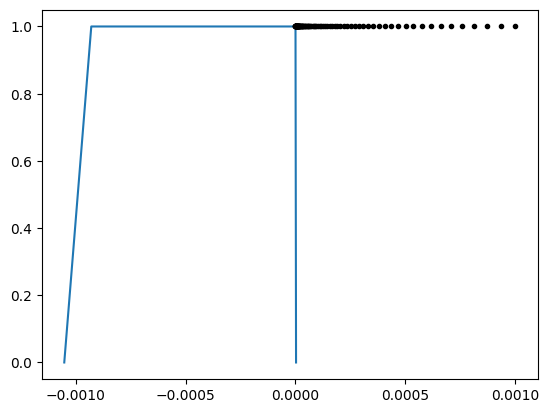

In [2]:
# tx = Loop.square(3.)
# rx = Receiver(x=9.)
tx = Loop.square(40.)
rx = Receiver(x=100)

wave = Waveform.example()
# t_wv = torch.concatenate([wave.time-2.e-3, wave.time])
# a_wv = torch.concatenate([-wave.amplitude, wave.amplitude])
# wave = Waveform(t_wv, a_wv)

t = torch.logspace(-9, -3, 201)

fwr = OnTimeForward(tx, rx, t, waveform=wave)

fwr0 = Forward(tx, rx, t, waveform=wave)
plt.figure()
plt.plot(wave.time, wave.amplitude, label='Waveform')
plt.plot(t, torch.ones_like(t), 'k.')

In [3]:
rho = torch.tensor([30, 40, 20])
thick = torch.tensor([20, 20])

dbdt = fwr(rho, thick)
dbdt0 = fwr0(rho, thick)

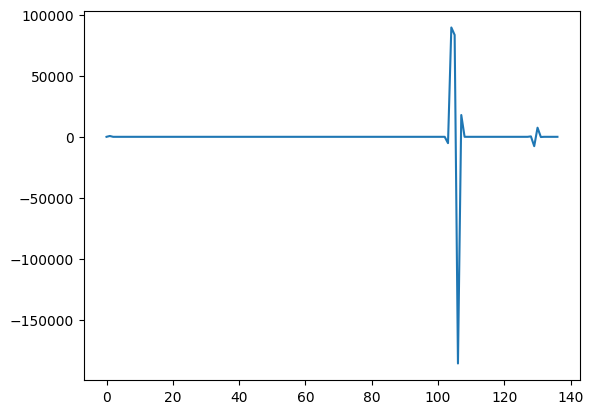

In [4]:
plt.figure()
plt.plot(fwr.t2t[150])

C:\Users\au646858\AppData\Local\Temp\ipykernel_29676\1173298697.py:1: RuntimeWarning: divide by zero encountered in log10
  plt.matshow(np.log10(np.abs(fwr.t2t)))


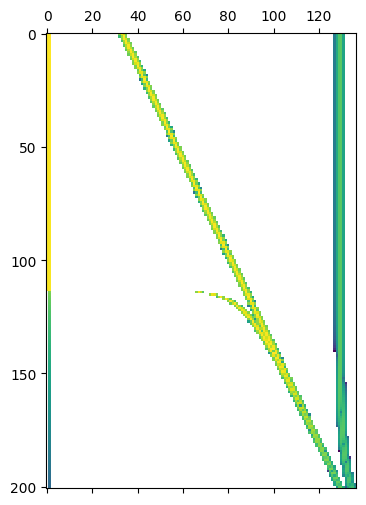

In [5]:
plt.matshow(np.log10(np.abs(fwr.t2t)))

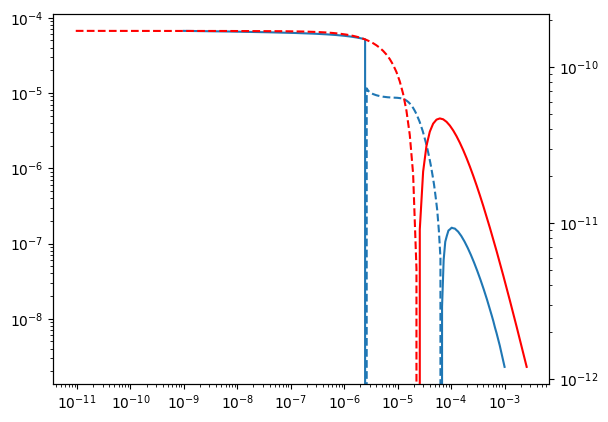

In [6]:
fig,ax = plt.subplots()

ax.loglog(t, dbdt)
ax.loglog(t, -dbdt, 'C0--')

# ax.semilogx(t,  dbdt0)
# ax.semilogx(t, -dbdt0, 'C1--')
ax2 = ax.twinx()
ax2.loglog(fwr.t_in, fwr.bstep[1:], 'r')
ax2.loglog(fwr.t_in, -fwr.bstep[1:], 'r--')
# ax.set_xlim(1e-5, 1e-3)
# t_wv = wave.time
# t_wv[-2] = 1e-9

# # ax2.loglog(fwr.t_in, fwr.bstep[1:], 'r')

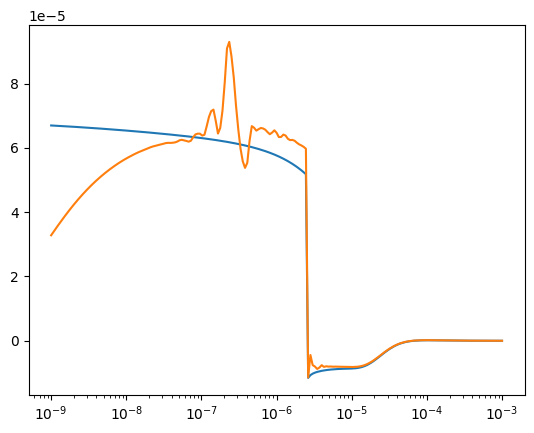

In [7]:
fig,ax = plt.subplots()

ax.semilogx(t, dbdt)
ax.semilogx(t, dbdt0)